In [1]:
# conda vis2
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go

PROJECT_ROOT = Path().resolve().parent.parent.parent
sys.path.append(str(PROJECT_ROOT))

In [2]:
import src.Retrieval as retrieval
from src.utils.util import set_labels

In [3]:
EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V10' / 'default'
r = retrieval.Retrieval(EXPERIMENT)
r.load_retrieval()

FIGURE_OUT = EXPERIMENT / 'figures'
FIGURE_OUT.mkdir(parents=True, exist_ok=True)

savefigs = True

# Figure: 3D Extinction

In [4]:
vmin = 0
vmax = 37.5

cloud = r.solvers_retrieval[0.67].medium['cloud']

X, Y, Z = np.meshgrid(cloud.x.data, cloud.y.data, cloud.z.data, indexing='ij')
data = go.Volume(
    x=X.flatten(),
    y=Y.flatten(),
    z=Z.flatten(),
    value=cloud.extinction.data.flatten(),
    isomin=vmin,
    isomax=vmax, 
    opacity=0.1,
    surface_count=17,
    showscale=True,
    colorbar=dict(
        title='Extinction',
        titleside='right',
        tickmode='array',
        tickvals=[vmin, 0.5*(vmin+vmax), vmax],
        ticktext=['Low', 'Medium', 'High'],
        len=0.8,
        thickness=20
    )
)
layout = go.Layout(autosize=False, width=750, height=650)
fig = go.Figure(data=data, layout=layout)
pad = {'b':0, 'l':0, 'r':0, 't':0, 'pad':0}
font = {'size':16}
scene = dict(
    xaxis=dict(title='x (km)', tickvals=[0, 4.4, 8.8, 13.2, 17.6], range=[-1, 18.6]),
    yaxis=dict(title='y (km)', tickvals=[0, 4.4, 8.8, 13.2, 17.6], range=[-1, 18.6]),
    zaxis=dict(title='z (km)', tickvals=[0, 1.4], range=[-0.1, 1.5]),
)

theta = np.radians(45)
phi = -0.3*np.pi
radius = 2.5
h = radius * np.sin(theta)

camera = dict(
    up=dict(x=0, y=0, z=1.0),
    center=dict(x=0.0, y=0.0, z=0.0),
    eye=dict(x=h*np.cos(phi), y=h*np.sin(phi), z=radius*np.cos(theta))
)
fig.update_layout(
    scene_camera=camera,
    margin=pad,
    font=font,
    scene=scene
)
if(savefigs):
    fig.write_image(FIGURE_OUT / '3D_extinction_{}.png'.format(r.iteration))

# Figure: extinction cross section

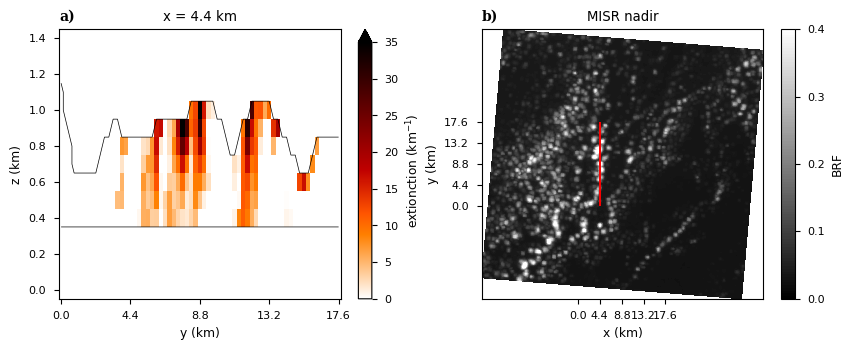

In [5]:
ext_cmap = 'gist_heat_r'
x = 4.4
vmax = 35
ticks = [0.0, 4.4, 8.8, 13.2, 17.6]

plt.style.use('seaborn-v0_8-paper')
f, ax = plt.subplots(1, 2, figsize=(10, 3.5))
cloud.sel(x=x, method='nearest').extinction.plot(
    y='z',
    ax=ax[0],
    vmin=0,
    vmax=vmax,
    cmap=ext_cmap,
    cbar_kwargs={'label': r'extionction (km$^{-1}$)'}
)
r.cvm.sel(x=x, method='nearest').cloud_volume_mask.plot.contour(
    y='z',
    levels=1, 
    ax=ax[0],
    colors='black',
    linewidths=0.5
)
ax[0].set_xlabel('y (km)')
ax[0].set_ylabel('z (km)')
ax[0].set_title('x = 4.4 km')
c = ax[1].tricontourf(
    r.obs['MISR']['sensor_list'][4].cam_x.data,
    r.obs['MISR']['sensor_list'][4].cam_y.data,
    r.obs['MISR']['sensor_list'][4].brf.data,
    cmap = 'gray',
    vmin = 0,
    vmax = 0.4,
    levels = np.linspace(0, 0.4, 100)
)
plt.colorbar(c, ax=ax[1], label='BRF', ticks=[0.0, 0.1, 0.2, 0.3, 0.4])

ax[1].vlines(x, 0, 17.6, colors='red')
ax[1].set_xlabel('x (km)')
ax[1].set_ylabel('y (km)')
ax[1].set_title('MISR nadir')
ax[0].set_xticks(ticks)
ax[1].set_xticks(ticks)
ax[1].set_yticks(ticks)

set_labels(ax.flatten())

if(savefigs):
    plt.savefig(
        FIGURE_OUT / 'extinction_transect_{}.png'.format(r.iteration),
        format='png',
        dpi=300,
        bbox_inches='tight',
        transparent=False
    )

# Figure: BRF

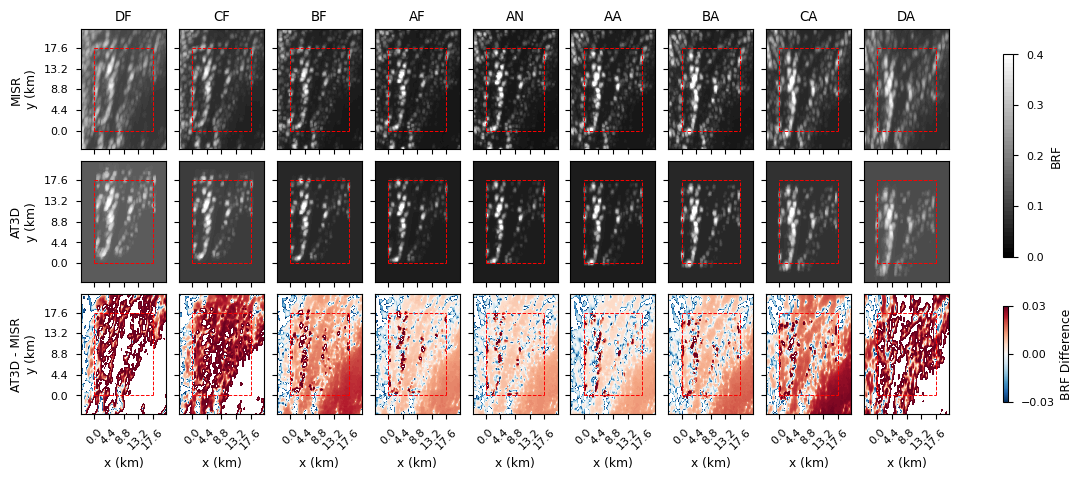

In [7]:
ticks = [0.0, 4.4, 8.8, 13.2, 17.6]
vrange = 0.03
plot_kwargs = {
    'cmap':'gray',
    'vmin':0,
    'vmax':0.4,
    'levels':np.linspace(0, 0.4, 50)
}
diff_kwargs = plot_kwargs.copy()
diff_kwargs['vmin'] = -vrange
diff_kwargs['vmax'] = vrange
diff_kwargs['cmap'] = 'RdBu_r'
diff_kwargs['levels'] = np.linspace(-vrange, vrange, 100)

misr_obs = r.obs['MISR']['sensor_list']
at3d_obs = r.sensors_retrieval['MISR']['sensor_list']

plt.style.use('seaborn-v0_8-paper')
f, ax = plt.subplots(3, 9, figsize=(14, 5), sharex=True, sharey=True)
plt.subplots_adjust(wspace=0.15, hspace=0.1)

for i, (mo, ao) in enumerate(zip(misr_obs, at3d_obs)):
    ax[0, i].tricontourf(mo.cam_x.data, mo.cam_y.data, mo.brf.data, **plot_kwargs)
    c1 = ax[1, i].tricontourf(ao.cam_x.data, ao.cam_y.data, ao.brf.data, **plot_kwargs)
    c2 = ax[2, i].tricontourf(ao.cam_x.data, ao.cam_y.data, ao.brf.data - mo.brf.data, **diff_kwargs)
    ax[0,i].set_title(mo.name)
    ax[2,i].set_xlabel('x (km)')
plt.colorbar(c1, ax=ax[0:2, :], label='BRF', shrink=0.8, ticks=[0.0, 0.1, 0.2, 0.3, 0.4])
plt.colorbar(c2, ax=ax[2,:], label='BRF Difference', shrink=0.8, ticks=[-vrange, 0.0, vrange])
ax[0, 0].set_ylabel('MISR\ny (km)')
ax[1, 0].set_ylabel('AT3D\ny (km)')
ax[2, 0].set_ylabel('AT3D - MISR\ny (km)')

box_kwargs = {'ls':'--', 'lw':0.7, 'c':'r'}
ticks = [0.0, 4.4, 8.8, 13.2, 17.6]
for a in ax.flat:
    a.plot([0, 0], [0, 17.6], **box_kwargs)
    a.plot([0, 17.6], [0, 0], **box_kwargs)
    a.plot([17.6, 17.6], [0, 17.6], **box_kwargs)
    a.plot([0, 17.6], [17.6, 17.6], **box_kwargs)
    a.set_xticks(ticks)
    a.set_xticklabels(ticks, rotation=45)
    a.set_yticks(ticks)
    a.set_xlim([-4,17.6+4])
    a.set_ylim([-4,17.6+4])
if(savefigs):
    plt.savefig(
        FIGURE_OUT / 'obs_vs_forward_sim_{}.png'.format(r.iteration),
        format='png',
        dpi=300,
        bbox_inches='tight',
        transparent=False
    )